# Stage 3: Data analysis

**Stage:** 3 (analysis) · **Runs on:** Kaggle and locally

| | |
|---|---|
| Input | the Stage 2 split files |
| Output | none: tables and plots are shown here for the report |

Describes the four datasets after cleaning and splitting: class balance, text length, the words
typical of each class, and possible **shortcuts** (words or styles that appear almost only in one
class, which a model could learn instead of the content). Word analysis uses the **training parts
only**, so nothing here looks at test data.

**On Kaggle:** attach the `misinfo_utils` utility script and add these notebooks as inputs (**Add Input → Your Work → Notebooks**): `02_split`.

In [1]:
# Setup: import the shared code. Works on Kaggle and locally.
import sys
from pathlib import Path

# Locally, misinfo_utils.py is in <project>/src/. On Kaggle it is an attached Utility Script,
# so this loop finds nothing and the import below still works.
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "src" / "misinfo_utils.py").exists():
        sys.path.insert(0, str(folder / "src"))
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import misinfo_utils as mu

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 100)
paths = mu.setup("03")

misinfo_utils | stage 03 | running on local
  read from : D:\misinfo-project\data\raw, D:\misinfo-project\outputs
  write to  : D:\misinfo-project\outputs\03_eda


## 1. Overview

In [2]:
clf = {ds: pd.concat([mu.load_split(ds, s) for s in mu.SPLITS], ignore_index=True) for ds in mu.DATASETS}
reg = pd.concat([mu.load_split("liar_reg", s) for s in mu.SPLITS], ignore_index=True)

overview = pd.DataFrame({
    ds: {"rows": len(df),
         "% misleading": round(100 * df["label"].mean(), 1),
         "median words": int(df["n_words"].median()),
         "mean words": round(df["n_words"].mean(), 1)}
    for ds, df in clf.items()}).T
overview   # for the report

,rows,% misleading,median words,mean words
liar,10163.0,55.5,16.0,17.7
welfake,20000.0,45.5,405.0,550.1
covid,10280.0,46.7,24.0,25.7
fakenewsnet,10348.0,49.4,11.0,11.3


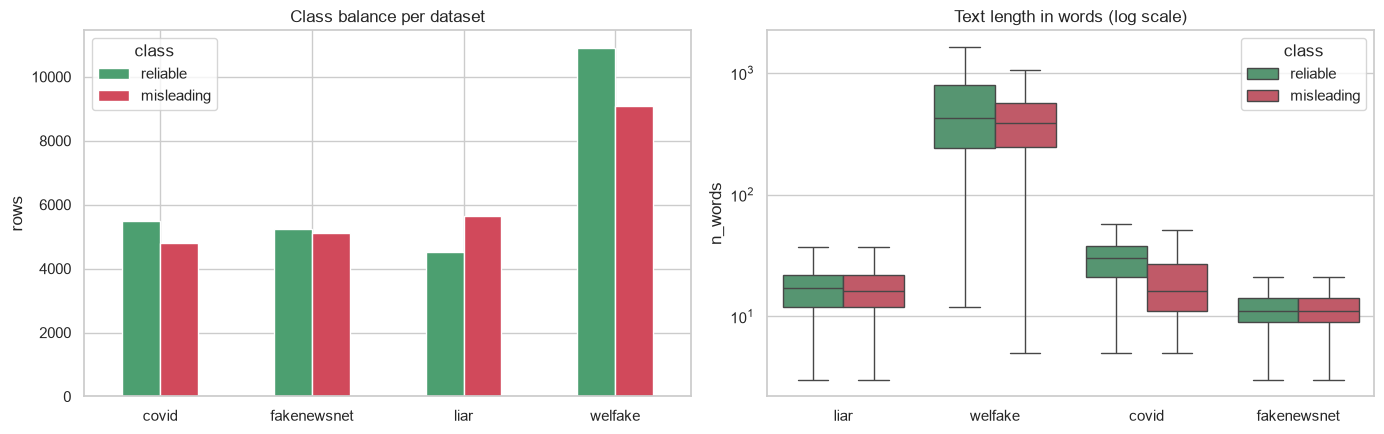

In [3]:
both = pd.concat(clf.values(), ignore_index=True)
both["class"] = both["label"].astype(int).map(mu.LABEL_NAMES)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
counts = both.groupby(["source_dataset", "class"]).size().unstack()[["reliable", "misleading"]]
counts.plot(kind="bar", ax=axes[0], rot=0, color=["#4C9F70", "#D1495B"])
axes[0].set_title("Class balance per dataset"); axes[0].set_xlabel(""); axes[0].set_ylabel("rows")

sns.boxplot(data=both, x="source_dataset", y="n_words", hue="class", ax=axes[1], showfliers=False,
            palette={"reliable": "#4C9F70", "misleading": "#D1495B"})
axes[1].set_yscale("log"); axes[1].set_title("Text length in words (log scale)"); axes[1].set_xlabel("")
paths["fig_dir"].mkdir(parents=True, exist_ok=True)
plt.tight_layout(); plt.savefig(paths["fig_dir"] / "fig1_balance_length.png", dpi=200); plt.show()

**Reading it:** text length differs hugely between datasets (headlines and claims vs full
articles), which is one reason every model is trained per dataset. A large length gap **between
classes** inside one dataset would be a shortcut worth mentioning.

## 2. LIAR ratings (regression target)

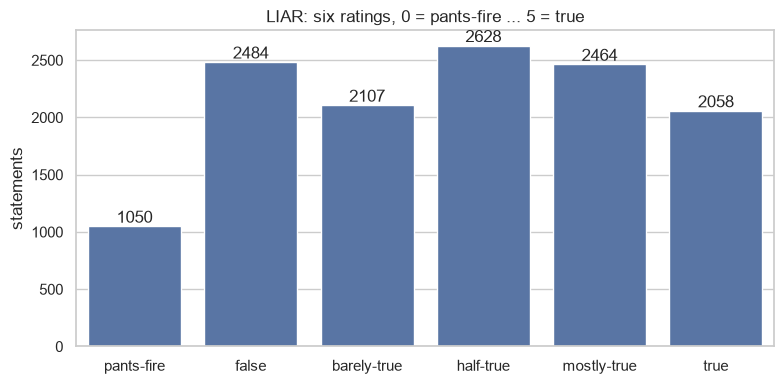

Mean score: 2.72 | standard deviation: 1.56


In [4]:
order = [mu.SCORE_NAMES[i] for i in range(6)]
plt.figure(figsize=(8, 4))
graph = sns.countplot(x=reg["score"].astype(int).map(mu.SCORE_NAMES), order=order, color="#4C72B0")
graph.bar_label(graph.containers[0])
plt.title("LIAR: six ratings, 0 = pants-fire ... 5 = true"); plt.xlabel(""); plt.ylabel("statements")
paths["fig_dir"].mkdir(parents=True, exist_ok=True)
plt.tight_layout(); plt.savefig(paths["fig_dir"] / "fig2_liar_ratings.png", dpi=200); plt.show()
print("Mean score:", round(reg["score"].mean(), 2), "| standard deviation:", round(reg["score"].std(), 2))

## 3. Words typical of each class, and shortcut words (training parts only)

* **Top words**: the most frequent words in each class (common words such as "the" removed).
* **Shortcut words**: words most strongly tied to one class (smoothed log-odds ratio, at least 5
  appearances). Names of publishers, hashtags or account names here would be shortcuts.

In [5]:
import re
from collections import Counter

STOP = set('''a an the and or but if of to in on at for with by from as is are was were be been being
it its this that these those he she they we you i his her their our your not no so than then there
has have had do does did will would can could should may might just also about into over after
before more most said says say what which who whom when where why how all any some such only own
same too very s t don now up out new one two'''.split())


def top_words(texts, n=12):
    c = Counter()
    for t in texts:
        c.update(w for w in re.findall(r"[a-z']+", t.lower()) if w not in STOP and len(w) > 2)
    return [w for w, _ in c.most_common(n)]


def shortcut_words(df, n=10, min_count=5):
    counts = {0: Counter(), 1: Counter()}
    for t, y in zip(df["text"], df["label"].astype(int)):
        counts[y].update(set(re.findall(r"[a-z#@']+", t.lower())))
    tot0, tot1 = max(sum(counts[0].values()), 1), max(sum(counts[1].values()), 1)
    rows = [(w, counts[0][w], counts[1][w], np.log(((counts[1][w] + 1) / tot1) / ((counts[0][w] + 1) / tot0)))
            for w in set(counts[0]) | set(counts[1]) if counts[0][w] + counts[1][w] >= min_count]
    out = pd.DataFrame(rows, columns=["word", "in_reliable", "in_misleading", "log_odds"])
    return out.nlargest(n, "log_odds"), out.nsmallest(n, "log_odds")


for ds in mu.DATASETS:
    train = mu.load_split(ds, "train")
    to_mis, to_rel = shortcut_words(train)
    print(f"===== {ds} =====")
    print("Top words, reliable   :", ", ".join(top_words(train.loc[train.label == 0, "text"])))
    print("Top words, misleading :", ", ".join(top_words(train.loc[train.label == 1, "text"])))
    print("Most 'misleading-only':", ", ".join(to_mis["word"]))
    print("Most 'reliable-only'  :", ", ".join(to_rel["word"]))
    print()

===== liar =====
Top words, reliable   : percent, state, year, years, tax, states, million, people, health, obama, texas, every
Top words, misleading : percent, obama, health, state, president, care, tax, people, year, years, bill, jobs
Most 'misleading-only': pelosi, scheme, christian, rob, deciding, frank, selling, face, story, showed
Most 'reliable-only'  : incarceration, latinos, bottom, charter, richest, latino, ratio, gunfire, heavily, youve

===== welfake =====
Top words, reliable   : trump, president, people, state, states, government, other, house, clinton, year, republican, united
Top words, misleading : trump, people, clinton, president, like, hillary, obama, them, donald, because, time, other
Most 'misleading-only': filessupport, sheeple, henningsen, wfb, acr, yr, conveniently, hesher, evangelists, savants
Most 'reliable-only'  : weekdays, rakhine, myanmar, kyi, aung, suu, rohingya, mariano, rajoy, corrects

===== covid =====
Top words, reliable   : cases, covid, tests, dea

## 4. Dataset-specific checks

In [6]:
checks = {}
fnn = clf["fakenewsnet"]
checks["FakeNewsNet: rows per site and class"] = fnn.groupby(["sub_source", "label"]).size().to_dict()
cov = clf["covid"]
checks["COVID: % that had a link before cleaning (reliable, misleading)"] = tuple(
    (cov.groupby("label")["had_url"].mean() * 100).round(1))
wel = clf["welfake"]
checks["WELFake: mean words (reliable, misleading)"] = tuple(wel.groupby("label")["n_words"].mean().round(1))
liar = clf["liar"]
says = liar["text"].str.startswith("Says ")
checks["LIAR: % misleading, starts with 'Says' vs other"] = (
    round(100 * liar.loc[says, "label"].astype(float).mean(), 1),     # nan if no statement starts with "Says"
    round(100 * liar.loc[~says, "label"].astype(float).mean(), 1))
for k, v in checks.items():
    print(f"{k:65s} {v}")

FakeNewsNet: rows per site and class                              {('gossipcop', 0): 4700, ('gossipcop', 1): 4700, ('politifact', 0): 533, ('politifact', 1): 415}
COVID: % that had a link before cleaning (reliable, misleading)   (68.9, 32.4)
WELFake: mean words (reliable, misleading)                        (585.4, 507.7)
LIAR: % misleading, starts with 'Says' vs other                   (np.float64(61.5), np.float64(53.8))


**For the report:** write two or three sentences per plot or table: what it shows, and what it
means for modelling (e.g. why LIAR is expected to be hardest, which shortcuts were removed in
Stage 1 and which remain).